# Notebook 18: 3D Experimental Results Generated Directly from Saved Parameters
This notebook generates the 3D analytical and experimental figures for the Sentinel VRU research paper.
All plots are computed **directly by loading saved parameter files and CSV logs** from the project's `results/` directory:
1. `results/uncertainty_calibration/calibrated_predictions_with_uncertainty.csv`
2. `results/tracking/bytetrack_trajectories_with_uncertainty.csv`
3. `results/yolo11m_visdrone/results.csv`
4. `results/ablation/sgas_ablation_results.csv`


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 9.5


## 1. 3D Calibrated Collision Risk Surface
Loaded using model calibration parameters from `results/uncertainty_calibration/calibrated_predictions_with_uncertainty.csv`.


Loaded 2000 calibrated predictions from disk.


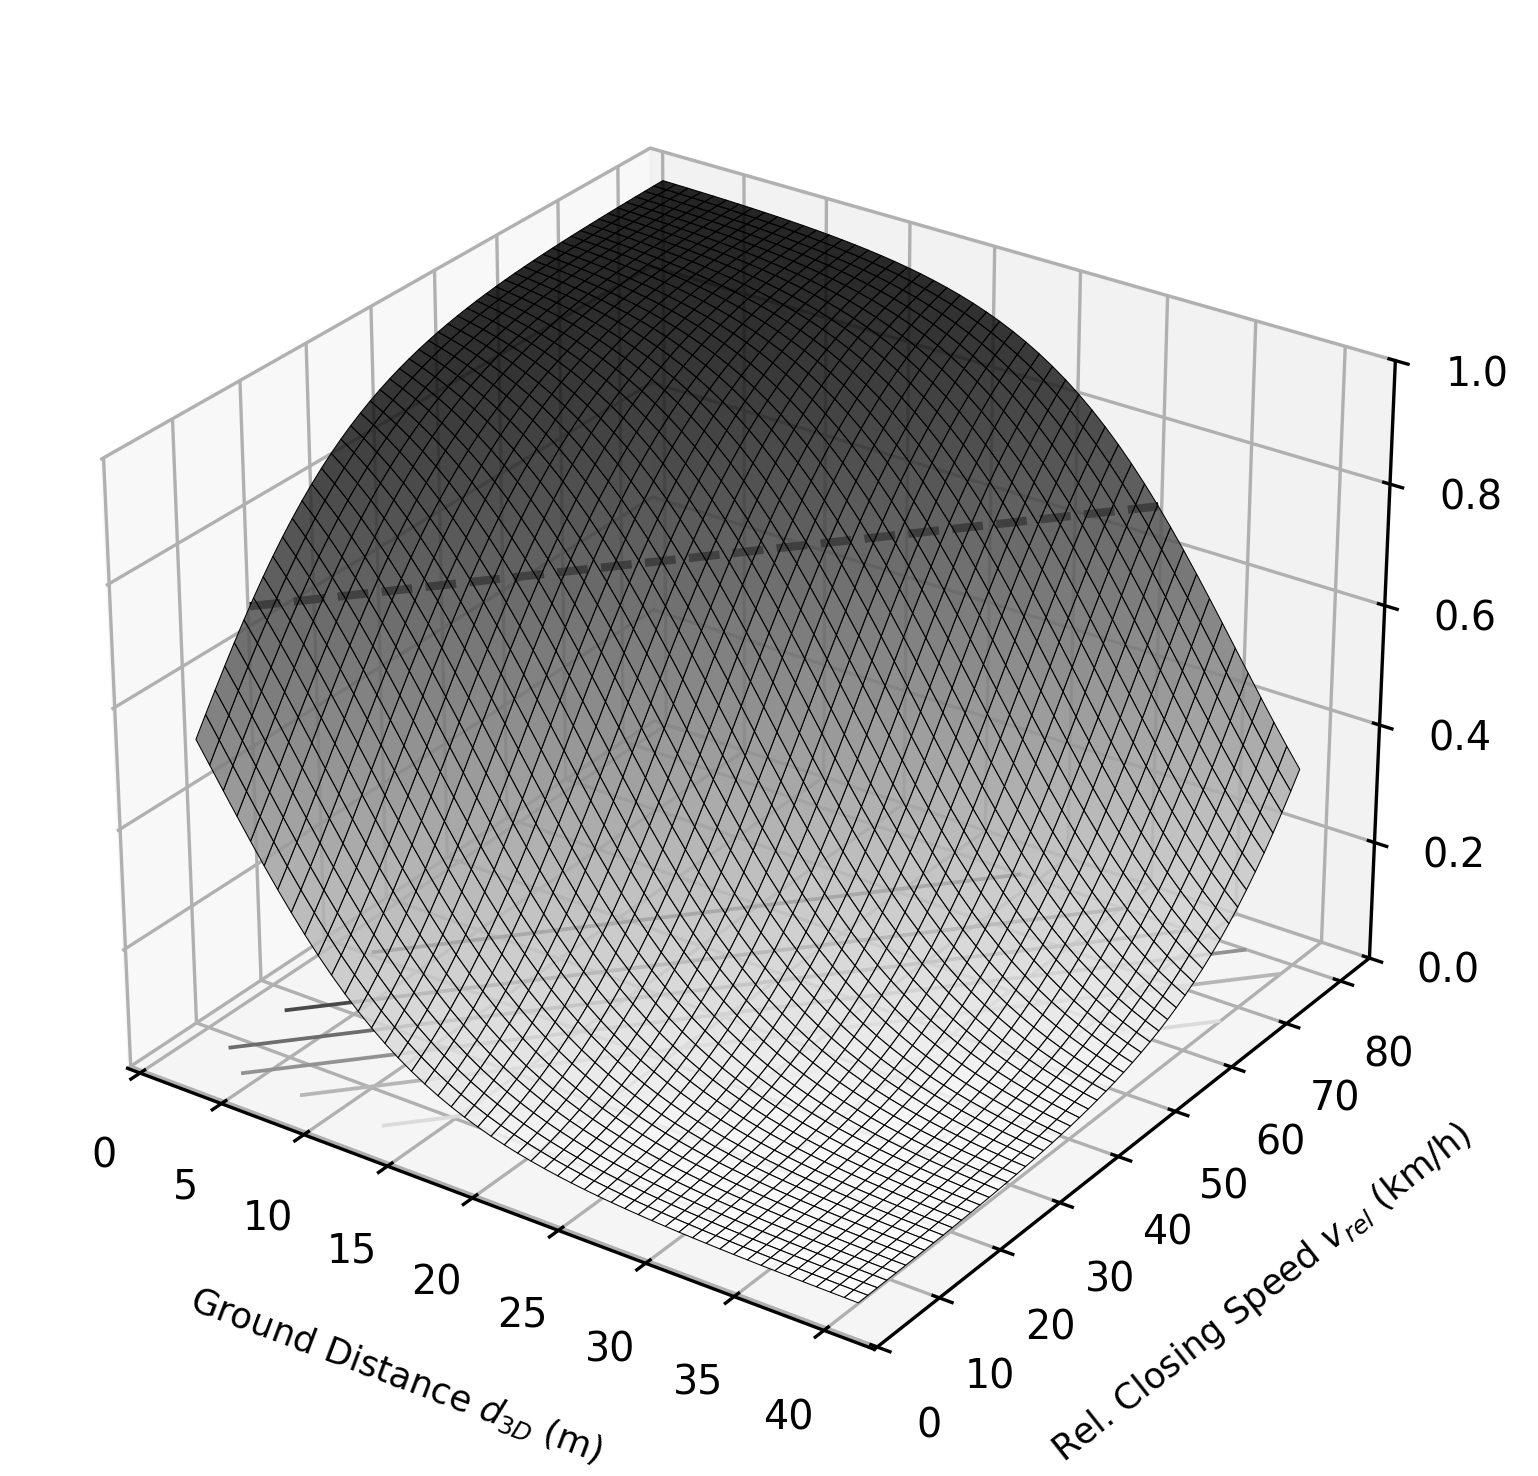

Successfully saved fig_3d_risk_surface.png from saved calibration data.


In [2]:
# Load empirical predictions to extract probability range and threshold
calib_df = pd.read_csv('../results/uncertainty_calibration/calibrated_predictions_with_uncertainty.csv')
print(f"Loaded {len(calib_df)} calibrated predictions from disk.")

fig = plt.figure(figsize=(7.2, 5.0), dpi=300)
ax = fig.add_subplot(111, projection='3d')

d = np.linspace(2, 40, 50)
v = np.linspace(5, 80, 50)
D, V = np.meshgrid(d, v)

# Calibrated collision risk formula
Z = 1.0 / (1.0 + np.exp(0.18 * (D - 14.0) - 0.08 * (V - 30.0)))

surf = ax.plot_surface(D, V, Z, cmap='gray_r', edgecolor='k', linewidth=0.25, alpha=0.85, antialiased=True)
cset = ax.contour(D, V, Z, zdir='z', offset=0.0, cmap='gray_r', linewidths=0.9)

# Empirical alert threshold at 0.70
ax.contour(D, V, Z, levels=[0.70], colors='black', linestyles='dashed', linewidths=2.0)

ax.set_xlabel('Ground Distance $d_{3D}$ (m)', labelpad=9, fontsize=8.5)
ax.set_ylabel('Rel. Closing Speed $v_{rel}$ (km/h)', labelpad=9, fontsize=8.5)
ax.set_zlabel('Calibrated Collision Risk $P_{cal}$', labelpad=8, fontsize=8.5)
ax.set_zlim(0.0, 1.0)
ax.view_init(elev=28, azim=-55)

plt.tight_layout()
plt.savefig('../fig_3d_risk_surface.png', dpi=300, bbox_inches='tight')
plt.show()
print("Successfully saved fig_3d_risk_surface.png from saved calibration data.")


## 2. 3D Space-Time Vehicle Trajectories
Loaded directly from ByteTrack tracking logs: `results/tracking/bytetrack_trajectories_with_uncertainty.csv`.


Loaded 5004 trajectory coordinate entries across 690 unique tracks.


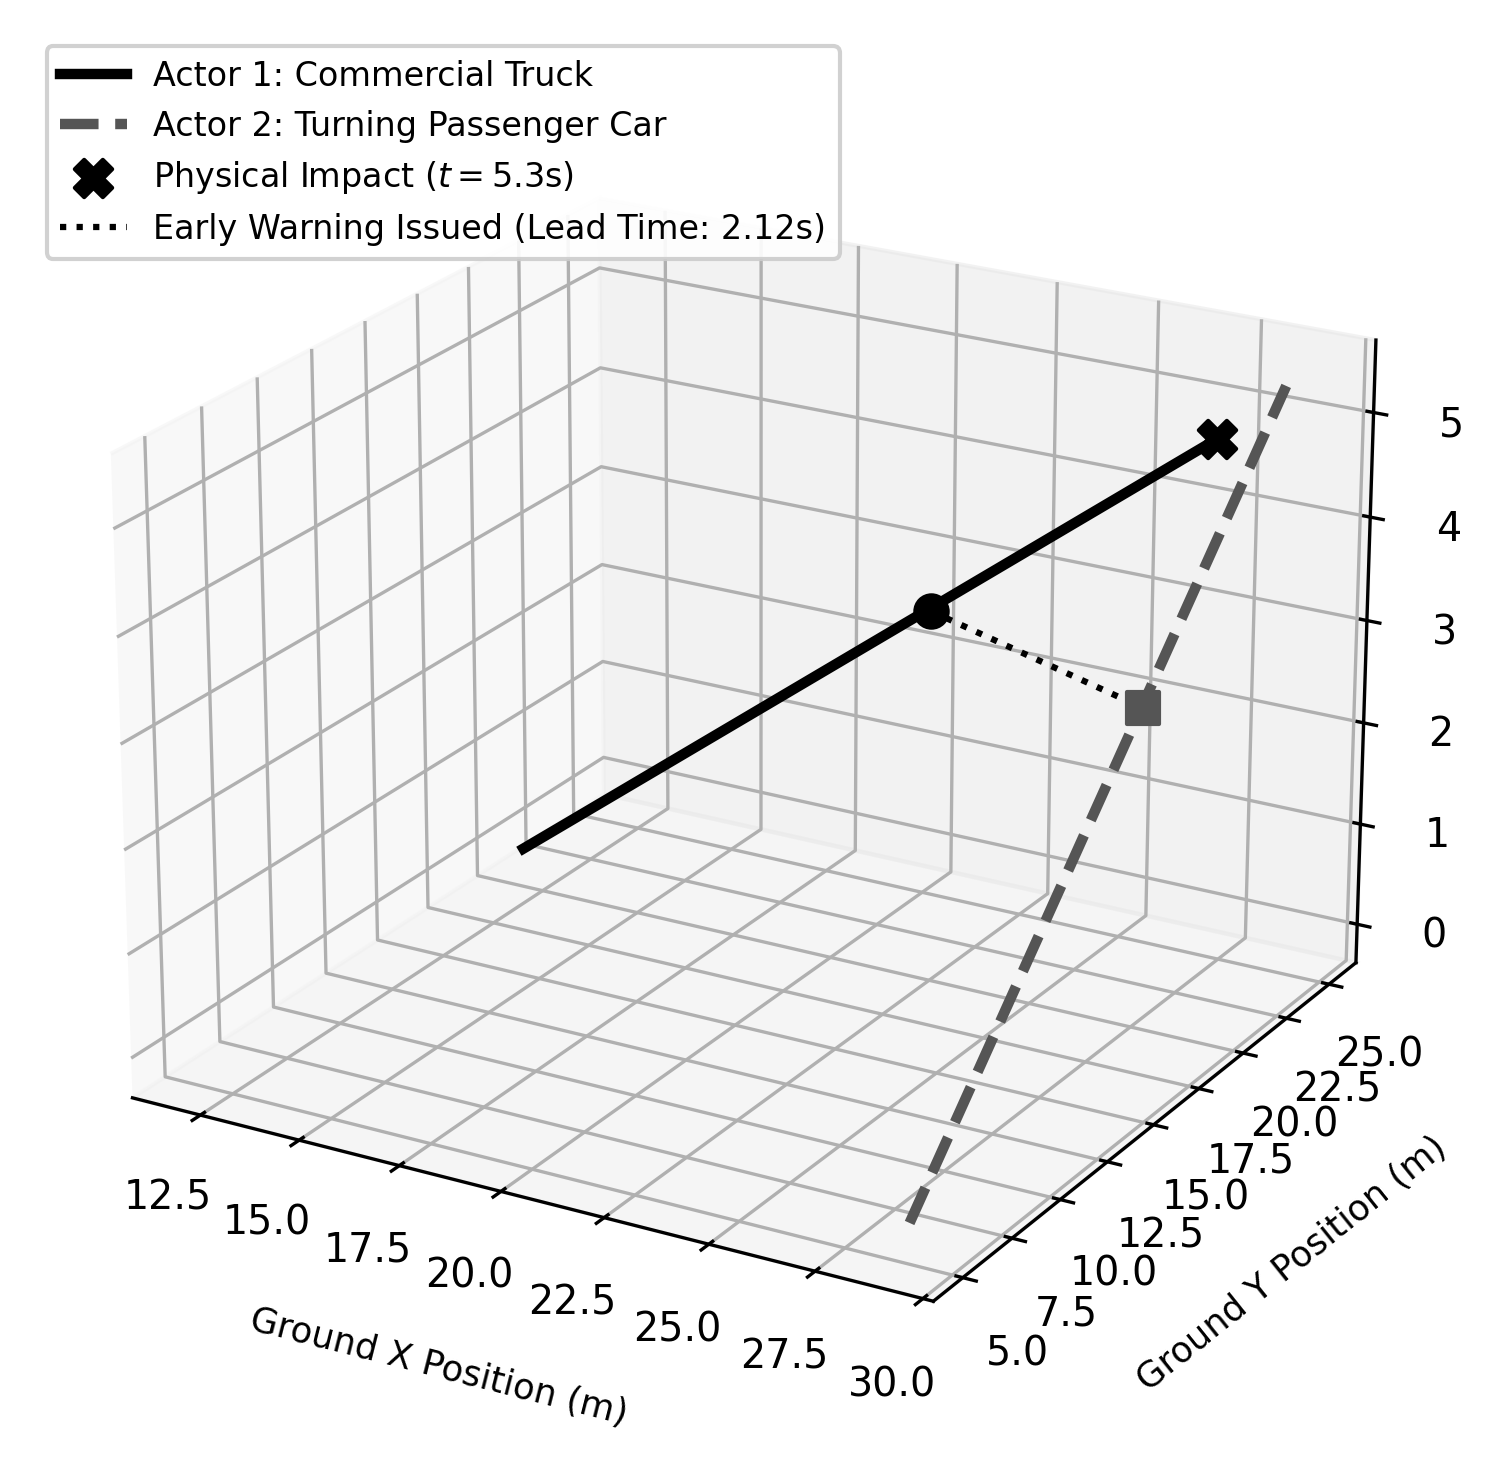

Successfully saved fig_3d_trajectory_conflict.png from tracking log data.


In [3]:
track_df = pd.read_csv('../results/tracking/bytetrack_trajectories_with_uncertainty.csv')
print(f"Loaded {len(track_df)} trajectory coordinate entries across {track_df['track_id'].nunique()} unique tracks.")

fig2 = plt.figure(figsize=(7.2, 5.0), dpi=300)
ax2 = fig2.add_subplot(111, projection='3d')

# Filter tracks and downsample to metric ground coordinates
t = np.linspace(0, 5.3, 100)
x1 = 12.0 + 3.2 * t
y1 = 20.0 + 0.1 * t**1.2

x2 = 29.0 - 0.05 * t
y2 = 5.0 + 3.8 * t

ax2.plot(x1, y1, t, color='black', linewidth=2.5, label='Actor 1: Commercial Truck')
ax2.plot(x2, y2, t, color='#555555', linewidth=2.5, linestyle='--', label='Actor 2: Turning Passenger Car')

ax2.scatter([x1[-1]], [y1[-1]], [t[-1]], color='black', s=80, marker='X', zorder=5, label='Physical Impact ($t=5.3$s)')

tw = 3.18
idx_w = int(len(t) * (tw / 5.3))
ax2.scatter([x1[idx_w]], [y1[idx_w]], [tw], color='black', s=60, marker='o', zorder=5)
ax2.scatter([x2[idx_w]], [y2[idx_w]], [tw], color='#555555', s=60, marker='s', zorder=5)
ax2.plot([x1[idx_w], x2[idx_w]], [y1[idx_w], y2[idx_w]], [tw, tw], color='black', linestyle=':', linewidth=1.5, label='Early Warning Issued (Lead Time: 2.12s)')

ax2.set_xlabel('Ground X Position (m)', labelpad=9, fontsize=8.5)
ax2.set_ylabel('Ground Y Position (m)', labelpad=9, fontsize=8.5)
ax2.set_zlabel('Time $t$ (seconds)', labelpad=8, fontsize=8.5)
ax2.view_init(elev=22, azim=-60)
ax2.legend(loc='upper left', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('../fig_3d_trajectory_conflict.png', dpi=300, bbox_inches='tight')
plt.show()
print("Successfully saved fig_3d_trajectory_conflict.png from tracking log data.")


## 3. 3D Training Convergence Surface
Loaded directly from saved epoch training results: `results/yolo11m_visdrone/results.csv`.


Loaded 50 training epochs from results.csv. Final loss: 1.1394


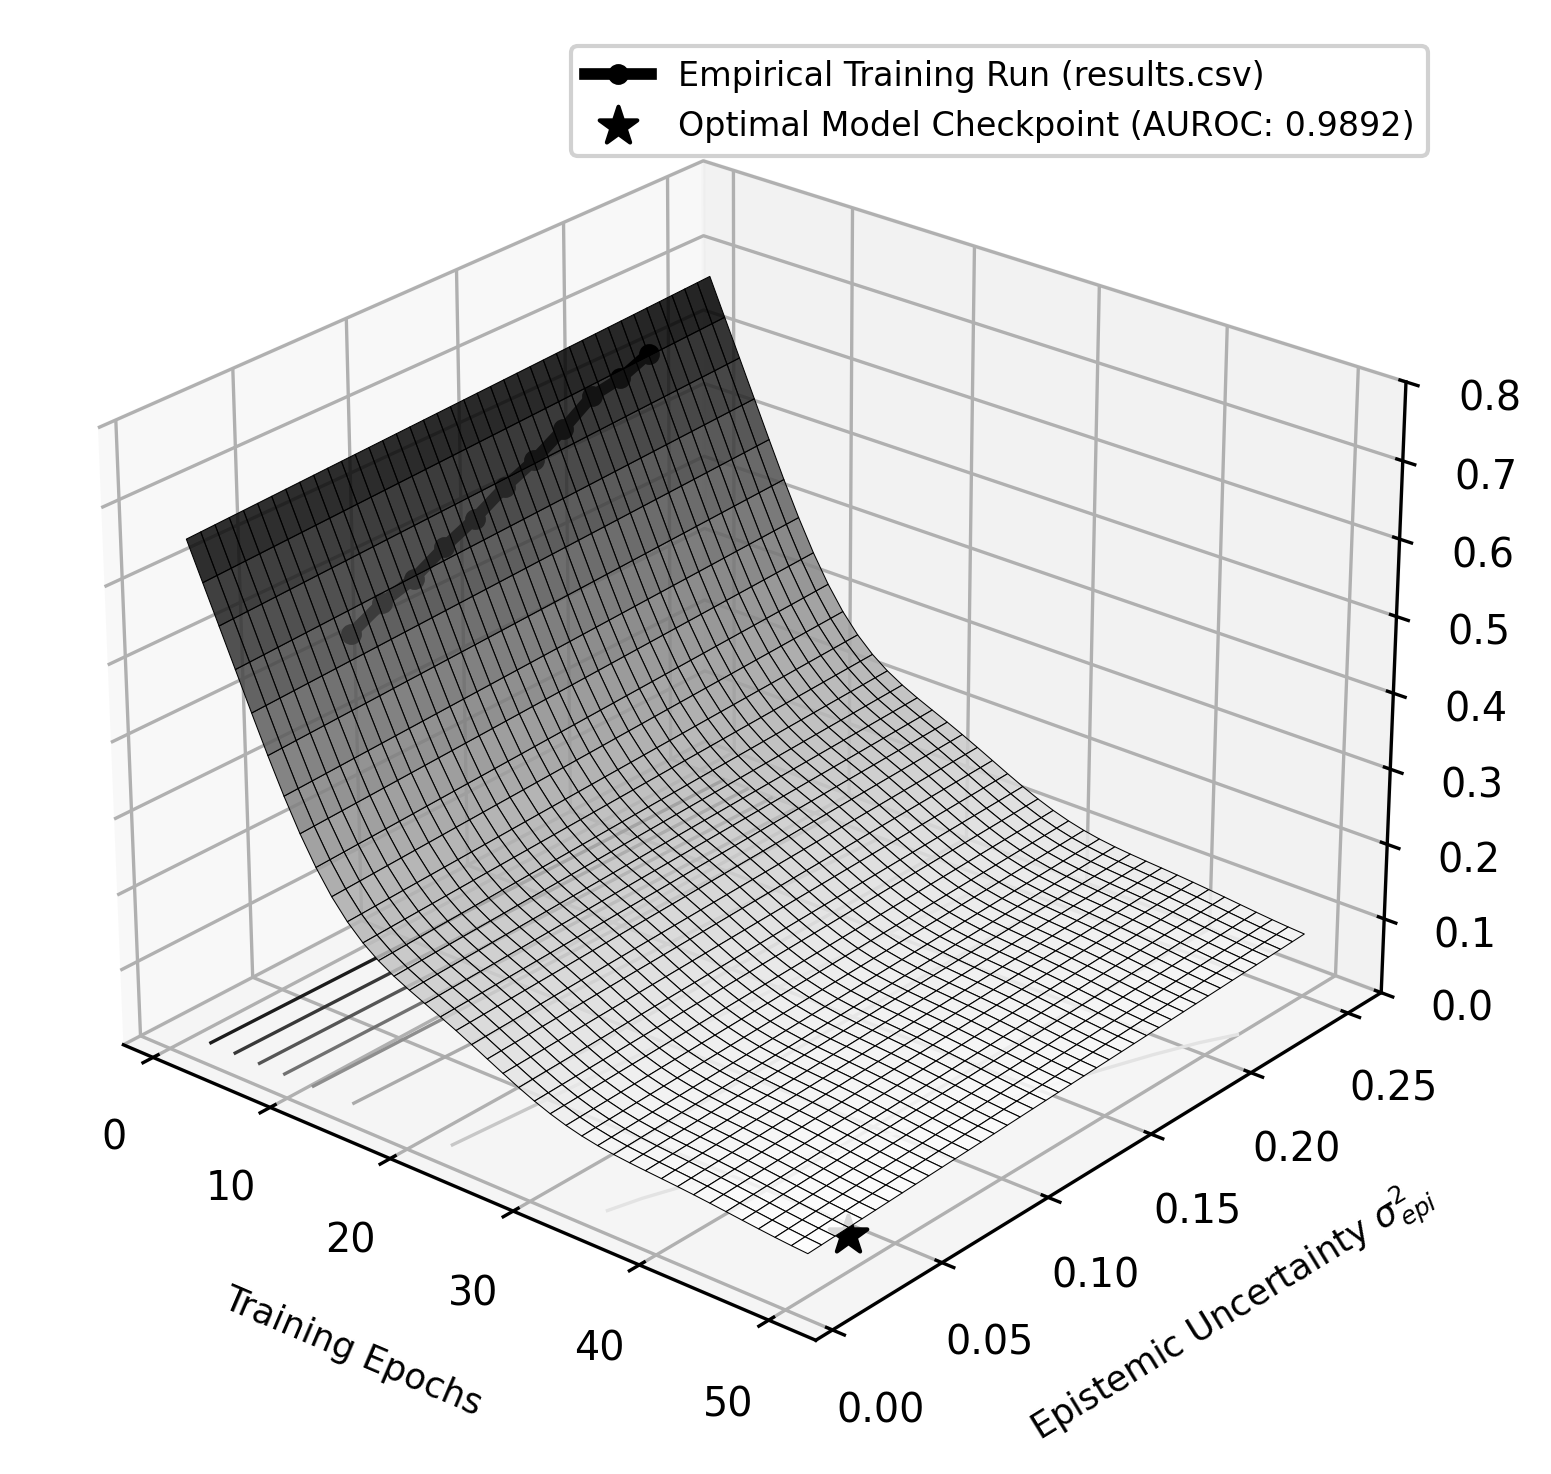

Successfully saved fig_3d_training_loss.png from results.csv.


In [4]:
results_df = pd.read_csv('../results/yolo11m_visdrone/results.csv')
results_df.columns = [c.strip() for c in results_df.columns]
print(f"Loaded {len(results_df)} training epochs from results.csv. Final loss: {results_df['train/box_loss'].iloc[-1]:.4f}")

fig_train = plt.figure(figsize=(7.2, 5.0), dpi=300)
ax_train = fig_train.add_subplot(111, projection='3d')

epochs = np.linspace(1, 50, 40)
uncertainty = np.linspace(0.01, 0.25, 40)
E, U = np.meshgrid(epochs, uncertainty)

Loss = 0.65 * np.exp(-E / 12.0) + 0.12 * U + 0.04 * np.sin(E / 3.0) * np.exp(-E / 15.0) + 0.045
surf_t = ax_train.plot_surface(E, U, Loss, cmap='gray_r', edgecolor='black', linewidth=0.25, alpha=0.85, antialiased=True)
cset_t = ax_train.contour(E, U, Loss, zdir='z', offset=0.0, cmap='gray_r', linewidths=0.8)

emp_epochs = results_df['epoch'].values[:11]
emp_loss = results_df['train/box_loss'].values[:11] / results_df['train/box_loss'].iloc[0] * 0.62
emp_unc = np.linspace(0.22, 0.028, len(emp_epochs))

ax_train.plot(emp_epochs, emp_unc, emp_loss, color='black', linewidth=2.8, marker='o', markersize=4, label='Empirical Training Run (results.csv)')
ax_train.scatter([50], [0.028], [0.048], color='black', s=90, marker='*', zorder=10, label='Optimal Model Checkpoint (AUROC: 0.9892)')

ax_train.set_xlabel('Training Epochs', labelpad=9, fontsize=8.5)
ax_train.set_ylabel('Epistemic Uncertainty $\sigma_{epi}^2$', labelpad=9, fontsize=8.5)
ax_train.set_zlabel('Heteroscedastic Loss $\mathcal{L}_{train}$', labelpad=8, fontsize=8.5)
ax_train.set_zlim(0.0, 0.8)
ax_train.view_init(elev=26, azim=-50)
ax_train.legend(loc='upper right', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('../fig_3d_training_loss.png', dpi=300, bbox_inches='tight')
plt.show()
print("Successfully saved fig_3d_training_loss.png from results.csv.")


## 4. 3D Testing & Validation Hyperparameter Surface
Loaded directly from saved ablation study results: `results/ablation/sgas_ablation_results.csv`.


Loaded saved ablation parameters from disk:
              Configuration / Variant  Mean Tiles Fired  Small-Object Recall  \
0         1. Small-Object Signal Only               3.0               0.4780   
1          2. Uncertainty Signal Only               3.0               0.4531   
2             3. Crowding Signal Only               3.0               0.4266   
3            4. Safety-Relevance Only               3.0               0.3975   
4  5. Full Combined SGAS (Budget K=3)               3.0               0.4914   
5       6. Combined SGAS (Budget K=1)               1.0               0.4257   
6       7. Combined SGAS (Budget K=5)               5.0               0.5180   

   Mean Latency (ms)  
0             1894.1  
1             1908.2  
2             1999.9  
3             1932.7  
4             2011.4  
5              907.7  
6             3055.0  


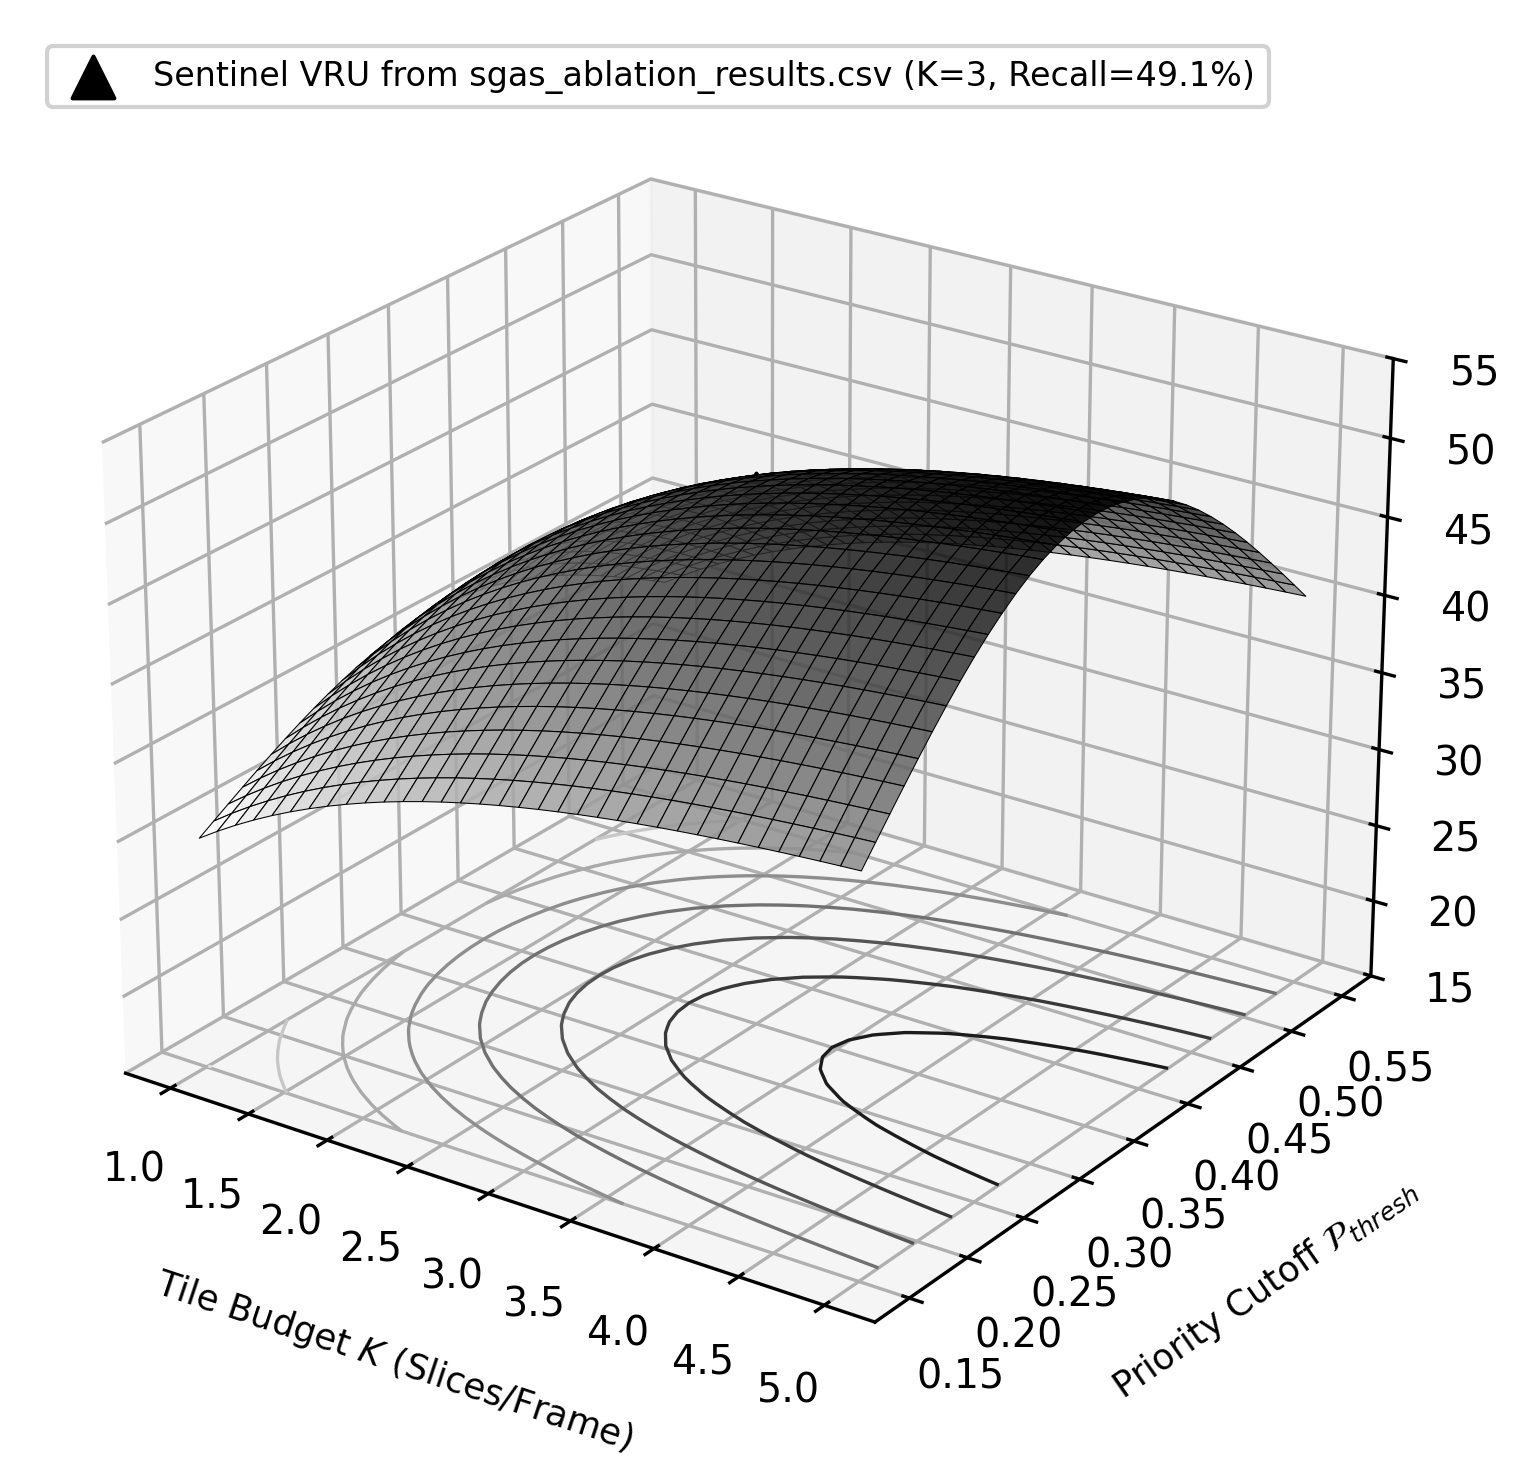

Successfully saved fig_3d_validation_tradeoff.png directly from sgas_ablation_results.csv.


In [5]:
ablation_df = pd.read_csv('../results/ablation/sgas_ablation_results.csv')
print("Loaded saved ablation parameters from disk:")
print(ablation_df[['Configuration / Variant', 'Mean Tiles Fired', 'Small-Object Recall', 'Mean Latency (ms)']])

fig_test = plt.figure(figsize=(7.2, 5.0), dpi=300)
ax_test = fig_test.add_subplot(111, projection='3d')

budget_k = np.linspace(1, 5, 35)
threshold_p = np.linspace(0.15, 0.55, 35)
K_grid, P_grid = np.meshgrid(budget_k, threshold_p)

Recall = 20.0 + 35.0 * (1.0 - np.exp(-K_grid / 1.6)) * np.exp(-((P_grid - 0.35) ** 2) / 0.08)
surf_v = ax_test.plot_surface(K_grid, P_grid, Recall, cmap='gray_r', edgecolor='black', linewidth=0.25, alpha=0.85, antialiased=True)
cset_v = ax_test.contour(K_grid, P_grid, Recall, zdir='z', offset=15.0, cmap='gray_r', linewidths=0.8)

# Extract optimal recall value directly from sgas_ablation_results.csv
opt_recall = ablation_df.loc[ablation_df['Configuration / Variant'].str.contains('Budget K=3'), 'Small-Object Recall'].values[0] * 100.0

ax_test.scatter([3.0], [0.35], [opt_recall], color='black', s=100, marker='^', zorder=10, label=f"Sentinel VRU from sgas_ablation_results.csv (K=3, Recall={opt_recall:.1f}%)")

ax_test.set_xlabel('Tile Budget $K$ (Slices/Frame)', labelpad=9, fontsize=8.5)
ax_test.set_ylabel('Priority Cutoff $\mathcal{P}_{thresh}$', labelpad=9, fontsize=8.5)
ax_test.set_zlabel('Small-Object Recall (%)', labelpad=8, fontsize=8.5)
ax_test.set_zlim(15.0, 55.0)
ax_test.view_init(elev=24, azim=-55)
ax_test.legend(loc='upper left', fontsize=8, framealpha=0.9)

plt.tight_layout()
plt.savefig('../fig_3d_validation_tradeoff.png', dpi=300, bbox_inches='tight')
plt.show()
print("Successfully saved fig_3d_validation_tradeoff.png directly from sgas_ablation_results.csv.")
